# Residential House Price Prediction


## 1. Import Libraries

In [1]:
# Data Analysis and Visualization Libraries
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

## 2. Load Dataset

In [2]:
# Load the training dataset
train_df = pd.read_csv(r"C:\Users\humai\Intern\PricePredict\Data\train.csv")

In [3]:
# Load the test dataset
test_df = pd.read_csv(r"C:\Users\humai\Intern\PricePredict\Data\test.csv")

## 3. Initial Data Understanding

In [4]:
# Data Shape
print("Training dataset shape:", train_df.shape)
print("Test dataset shape:", test_df.shape)

Training dataset shape: (1460, 81)
Test dataset shape: (1459, 80)


In [5]:
# First 5 rows of the training dataset
display(train_df.head())

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [6]:
# Last 5 rows of the training dataset
display(train_df.tail())

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
1455,1456,60,RL,62.0,7917,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,8,2007,WD,Normal,175000
1456,1457,20,RL,85.0,13175,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,2,2010,WD,Normal,210000
1457,1458,70,RL,66.0,9042,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,GdPrv,Shed,2500,5,2010,WD,Normal,266500
1458,1459,20,RL,68.0,9717,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,142125
1459,1460,20,RL,75.0,9937,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,6,2008,WD,Normal,147500


In [7]:
# Column Names
print(train_df.columns.tolist())

['Id', 'MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'MasVnrArea', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1', 'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual', 'TotRmsAbvGrd', 'Functional', 'Fireplaces', 'FireplaceQu', 'GarageType', 'GarageYrBlt', 'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual', 'GarageCond', 'PavedDrive', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'PoolQC'

In [8]:
# Data Types
display(train_df.dtypes.to_frame("Data Type"))

,Data Type
Id,int64
MSSubClass,int64
MSZoning,str
LotFrontage,float64
LotArea,int64
...,...
MoSold,int64
YrSold,int64
SaleType,str
SaleCondition,str


In [9]:
# Dataset Information
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallCond    1460

In [10]:
# Numerical Summary Statistics
display(train_df.describe())

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [11]:
# Categorical Summary Statistics
display(train_df.describe(include="object"))


,MSZoning,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,...,GarageType,GarageFinish,GarageQual,GarageCond,PavedDrive,PoolQC,Fence,MiscFeature,SaleType,SaleCondition
count,1460,1460,91,1460,1460,1460,1460,1460,1460,1460,...,1379,1379,1379,1379,1460,7,281,54,1460,1460
unique,5,2,2,4,4,2,5,3,25,9,...,6,3,5,5,3,3,4,4,9,6
top,RL,Pave,Grvl,Reg,Lvl,AllPub,Inside,Gtl,NAmes,Norm,...,Attchd,Unf,TA,TA,Y,Gd,MnPrv,Shed,WD,Normal
freq,1151,1454,50,925,1311,1459,1052,1382,225,1260,...,870,605,1311,1326,1340,3,157,49,1267,1198


In [12]:
# Numerical and Categorical Columns
numerical_cols = train_df.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_cols = train_df.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical columns:", len(numerical_cols))
print("Categorical columns:", len(categorical_cols))

Numerical columns: 38
Categorical columns: 43


## 4. Data Quality Investigation

In [13]:
 # Missing Values
missing_values = train_df.isnull().sum()

missing_percentage = (
    missing_values / len(train_df)
) * 100

missing_df = pd.DataFrame({
    "Missing Values": missing_values,
    "Percentage": missing_percentage
})

missing_df = missing_df[
    missing_df["Missing Values"] > 0
].sort_values(
    "Percentage",
    ascending=False
)

display(missing_df)

,Missing Values,Percentage
PoolQC,1453,99.520548
MiscFeature,1406,96.301370
Alley,1369,93.767123
Fence,1179,80.753425
MasVnrType,872,59.726027
FireplaceQu,690,47.260274
LotFrontage,259,17.739726
GarageType,81,5.547945
GarageYrBlt,81,5.547945
GarageFinish,81,5.547945


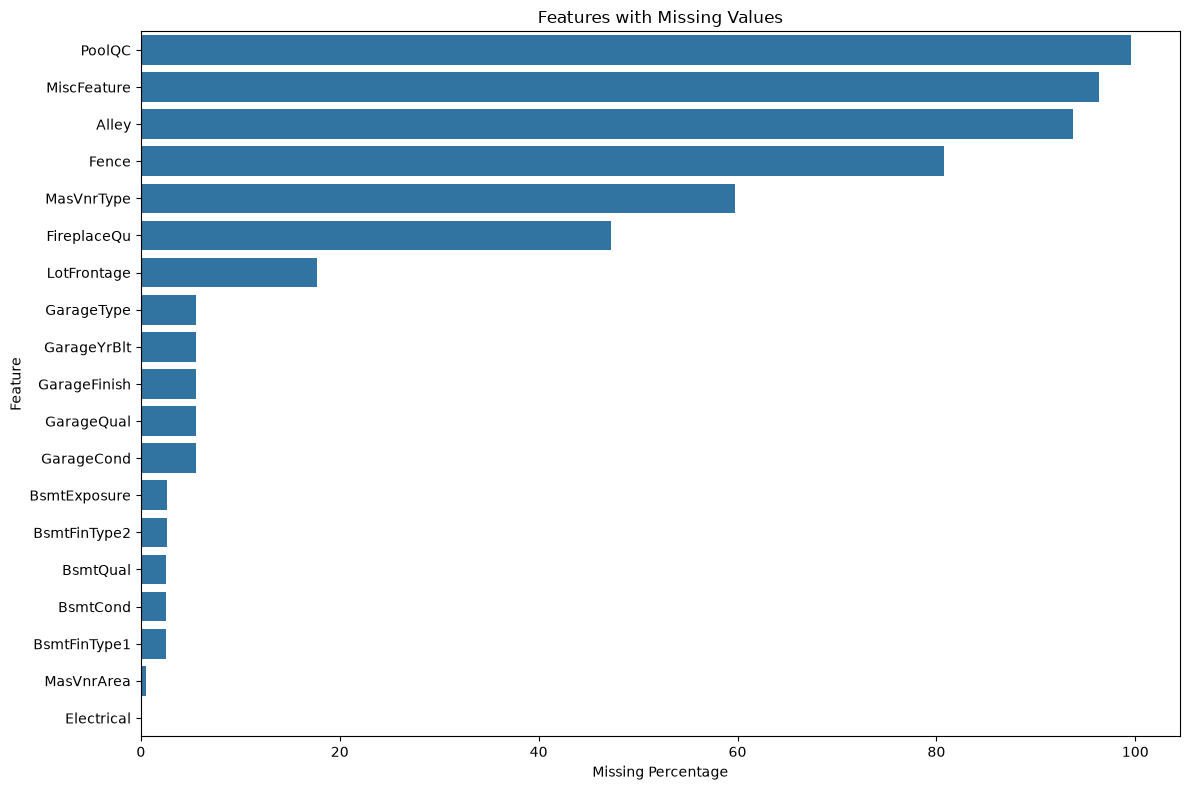

In [14]:
# Missing Values Visualization
plt.figure(figsize=(12, 8))

sns.barplot(
    data=missing_df.head(30),
    x="Percentage",
    y=missing_df.head(30).index
)

plt.title("Features with Missing Values")
plt.xlabel("Missing Percentage")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [15]:
# Duplicate Rows
print(
    "Duplicate rows:",
    train_df.duplicated().sum()
)

Duplicate rows: 0


In [16]:
# Unique Values
unique_values = train_df.nunique().sort_values()

display(
    unique_values.to_frame("Unique Values")
)

,Unique Values
Alley,2
Street,2
Utilities,2
CentralAir,2
MasVnrType,3
...,...
1stFlrSF,753
BsmtUnfSF,780
GrLivArea,861
LotArea,1073


In [17]:
# Constant Columns
constant_columns = unique_values[
    unique_values == 1
]

print("Constant columns:")

if len(constant_columns) == 0:
    print("No constant columns found.")
else:
    display(constant_columns)

Constant columns:
No constant columns found.


## 5. Target Variable Analysis

In [18]:
# Define Target
target = "SalePrice"

In [19]:
# Target Statistics
display(
    train_df[target].describe()
)

count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

In [20]:
# Target Skewness
print(
    "SalePrice skewness:",
    train_df[target].skew()
)

SalePrice skewness: 1.8828757597682129


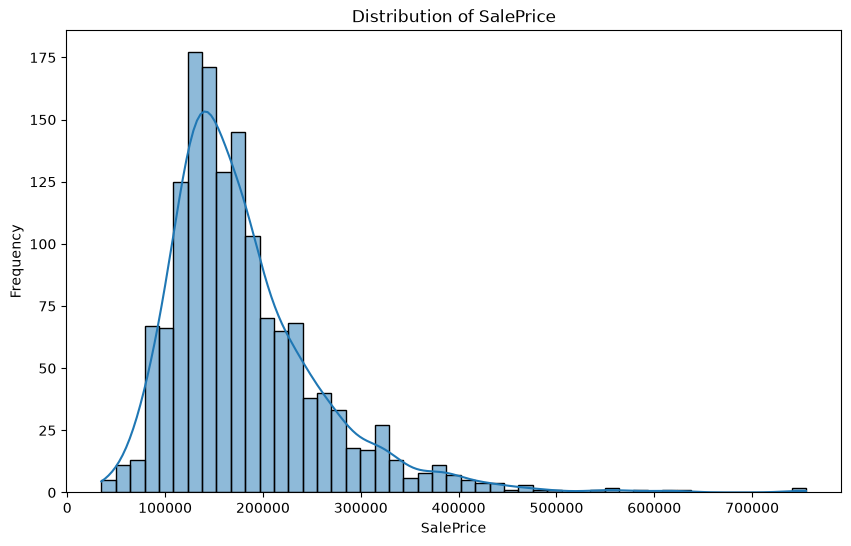

In [21]:
# SalePrice Distribution
plt.figure(figsize=(10, 6))

sns.histplot(
    train_df["SalePrice"],
    kde=True
)

plt.title("Distribution of SalePrice")
plt.xlabel("SalePrice")
plt.ylabel("Frequency")

plt.show()

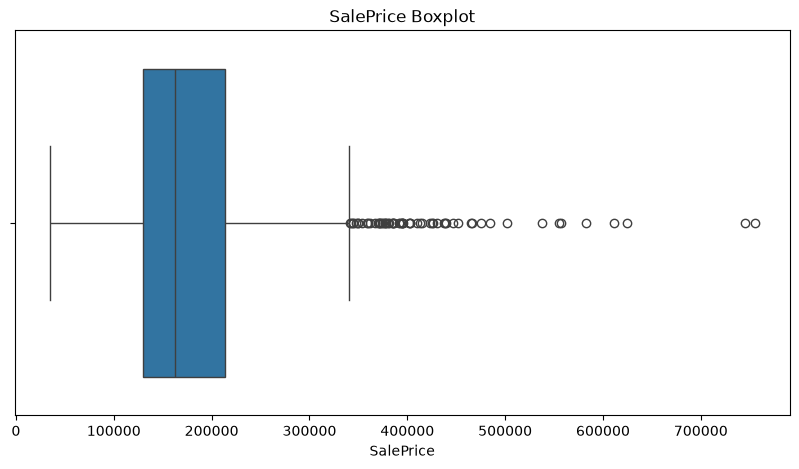

In [22]:
# SalePrice Boxplot
plt.figure(figsize=(10, 5))

sns.boxplot(
    x=train_df["SalePrice"]
)

plt.title("SalePrice Boxplot")
plt.xlabel("SalePrice")

plt.show()

## 6. SalePrice Log Transformation

In [23]:
# Apply Log Transformation
train_df["LogSalePrice"] = np.log1p(
    train_df["SalePrice"]
)


In [24]:
# Compare Skewness
print(
    "Original skewness:",
    train_df["SalePrice"].skew()
)

print(
    "Log-transformed skewness:",
    train_df["LogSalePrice"].skew()
)

Original skewness: 1.8828757597682129
Log-transformed skewness: 0.12134661989685333


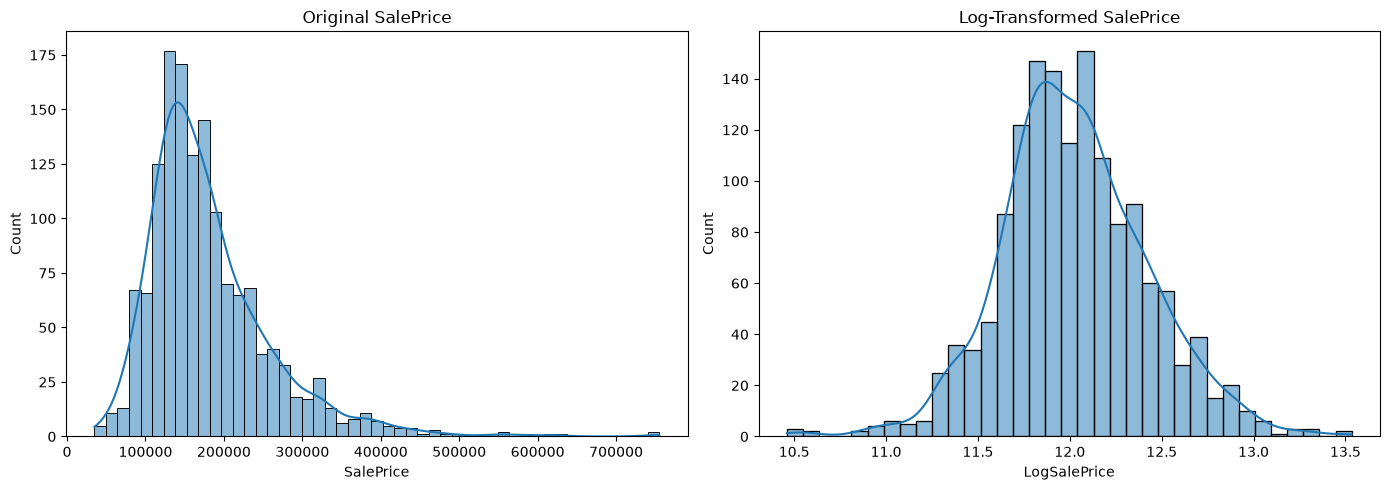

In [25]:
# Compare Distributions
fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5)
)

sns.histplot(
    train_df["SalePrice"],
    kde=True,
    ax=axes[0]
)

axes[0].set_title("Original SalePrice")

sns.histplot(
    train_df["LogSalePrice"],
    kde=True,
    ax=axes[1]
)

axes[1].set_title("Log-Transformed SalePrice")

plt.tight_layout()
plt.show()

## 7. Numerical Feature EDA

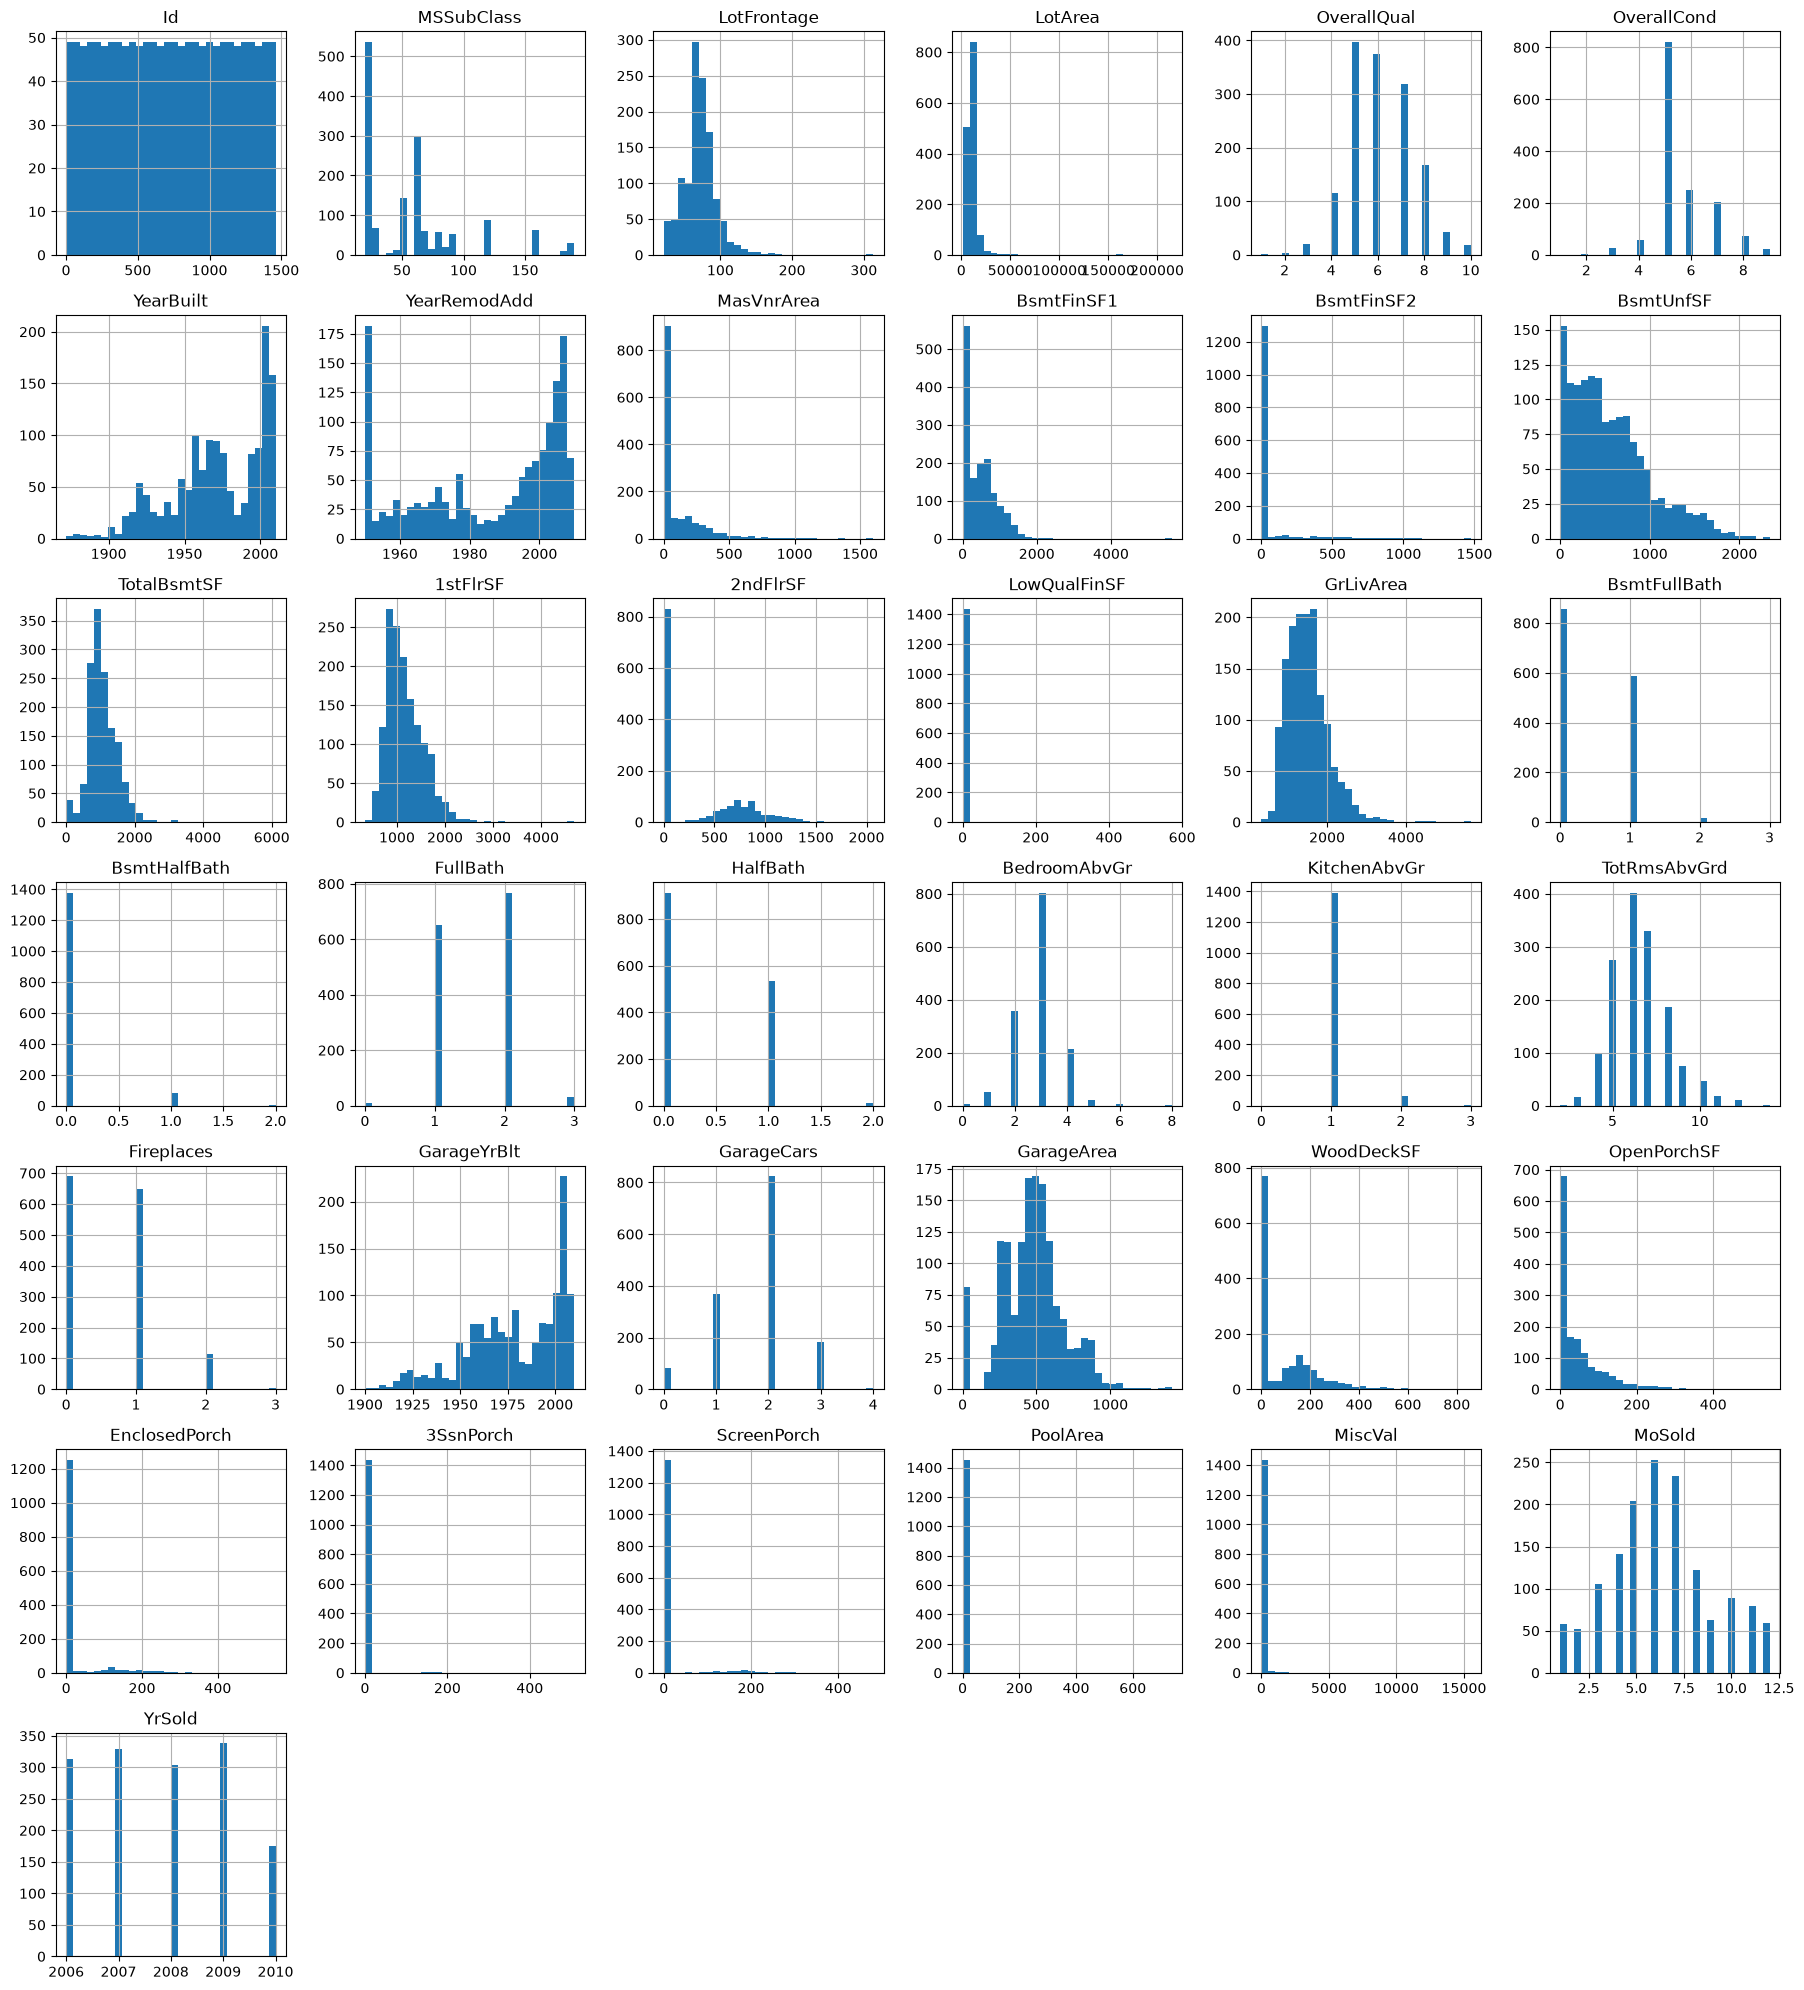

In [26]:
# Numerical Feature Distributions
eda_numerical_cols = train_df.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

eda_numerical_cols.remove("SalePrice")
eda_numerical_cols.remove("LogSalePrice")

train_df[eda_numerical_cols].hist(
    figsize=(18, 20),
    bins=30
)

plt.tight_layout()
plt.show()


In [27]:
# Numerical Feature Skewness
numerical_skewness = (
    train_df[eda_numerical_cols]
    .skew()
    .sort_values(ascending=False)
)

display(
    numerical_skewness.to_frame("Skewness")
)


,Skewness
MiscVal,24.476794
PoolArea,14.828374
LotArea,12.207688
3SsnPorch,10.304342
LowQualFinSF,9.011341
KitchenAbvGr,4.488397
BsmtFinSF2,4.255261
ScreenPorch,4.122214
BsmtHalfBath,4.103403
EnclosedPorch,3.089872


In [28]:
# Correlation with SalePrice
correlations = (
    train_df[
        eda_numerical_cols + ["SalePrice"]
    ]
    .corr()["SalePrice"]
    .drop("SalePrice")
    .sort_values(ascending=False)
)

display(
    correlations.to_frame(
        "Correlation with SalePrice"
    )
)


,Correlation with SalePrice
OverallQual,0.790982
GrLivArea,0.708624
GarageCars,0.640409
GarageArea,0.623431
TotalBsmtSF,0.613581
1stFlrSF,0.605852
FullBath,0.560664
TotRmsAbvGrd,0.533723
YearBuilt,0.522897
YearRemodAdd,0.507101


In [29]:
# Top Correlated Features
top_correlations = (
    correlations.abs()
    .sort_values(ascending=False)
    .head(15)
)

display(
    top_correlations.to_frame(
        "Absolute Correlation"
    )
)


,Absolute Correlation
OverallQual,0.790982
GrLivArea,0.708624
GarageCars,0.640409
GarageArea,0.623431
TotalBsmtSF,0.613581
1stFlrSF,0.605852
FullBath,0.560664
TotRmsAbvGrd,0.533723
YearBuilt,0.522897
YearRemodAdd,0.507101


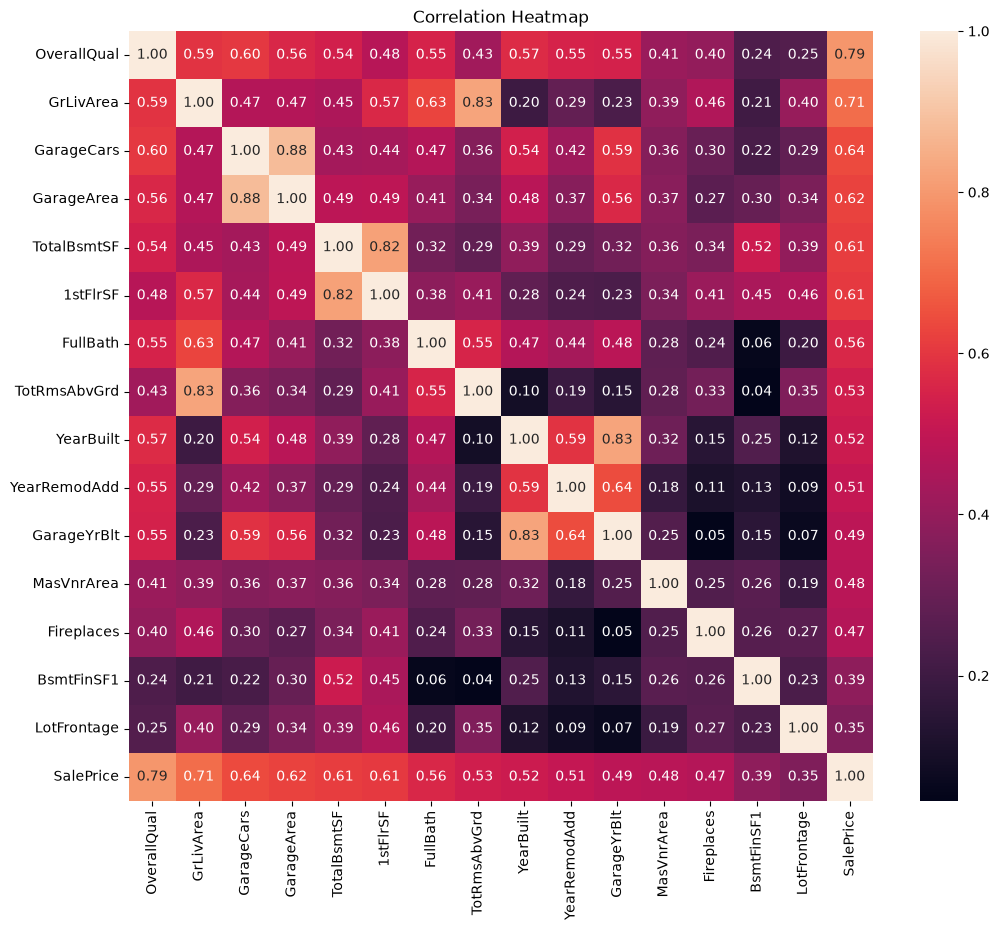

In [30]:
# Correlation Heatmap
heatmap_features = (
    top_correlations.index.tolist()
    + ["SalePrice"]
)

plt.figure(figsize=(12, 10))

sns.heatmap(
    train_df[heatmap_features].corr(),
    annot=True,
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.show()


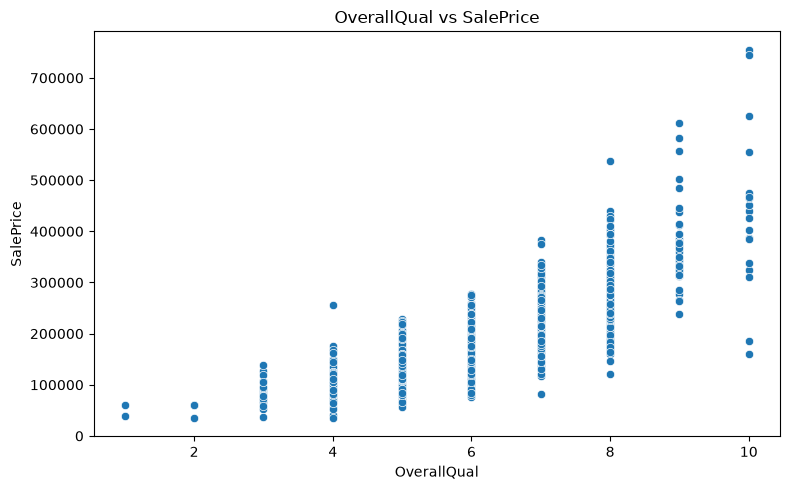

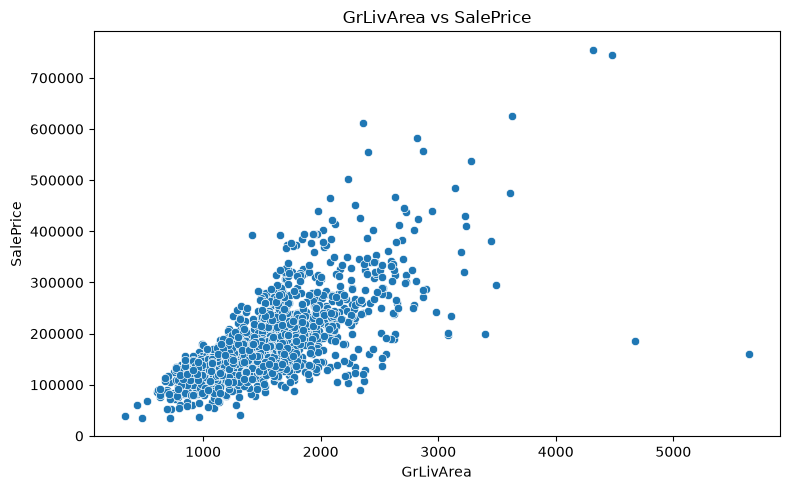

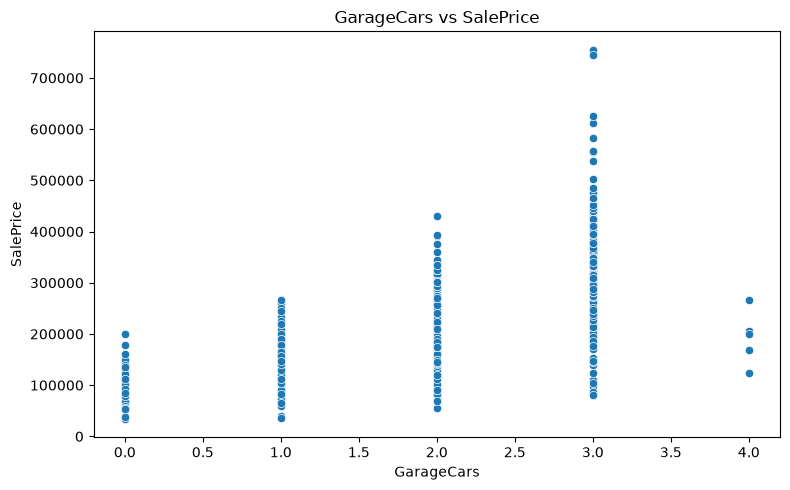

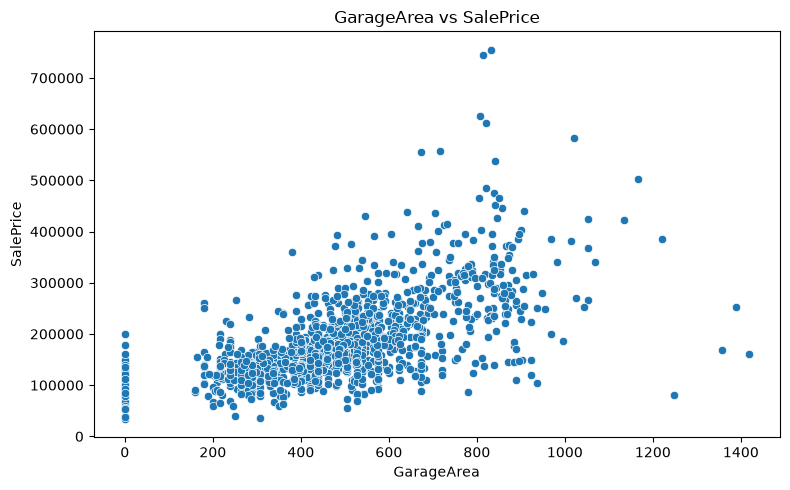

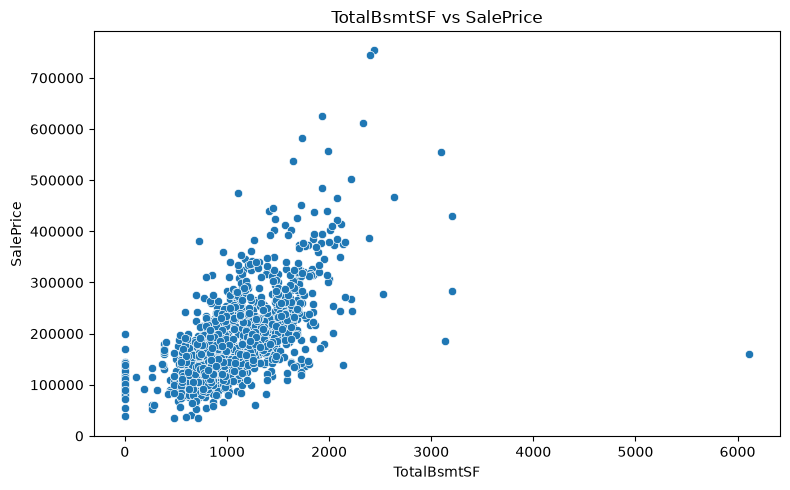

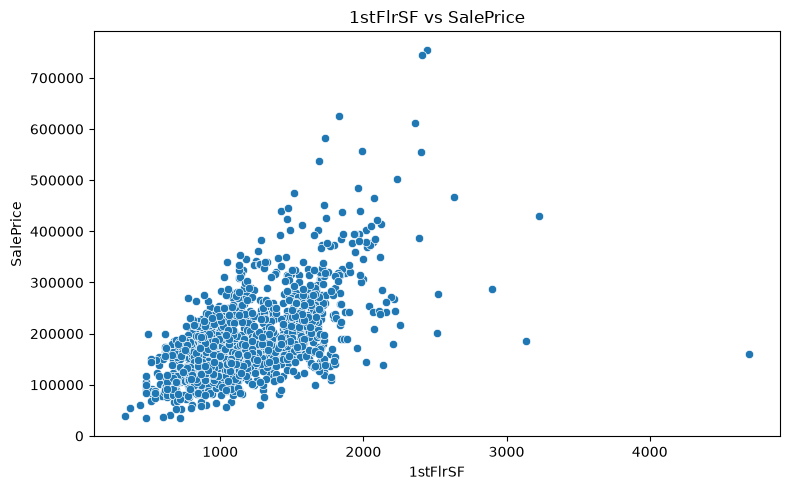

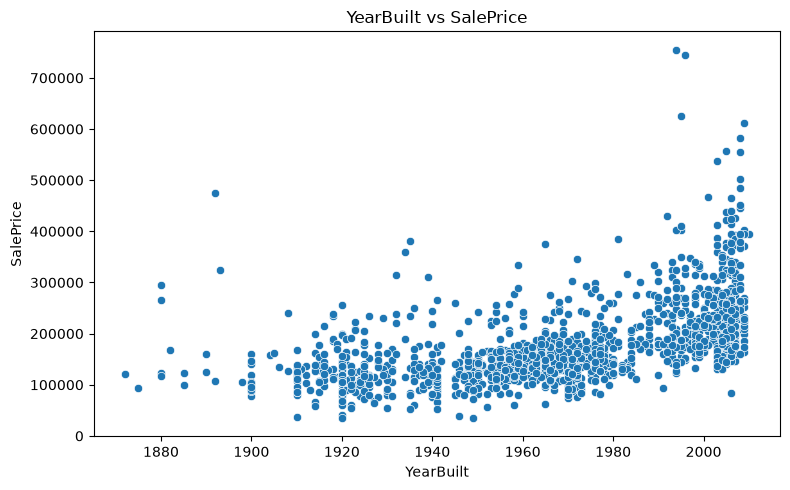

In [31]:
# Important Numerical Features vs SalePrice
important_numerical_features = [
    "OverallQual",
    "GrLivArea",
    "GarageCars",
    "GarageArea",
    "TotalBsmtSF",
    "1stFlrSF",
    "YearBuilt"
]

for feature in important_numerical_features:

    plt.figure(figsize=(8, 5))

    sns.scatterplot(
        data=train_df,
        x=feature,
        y="SalePrice"
    )

    plt.title(
        f"{feature} vs SalePrice"
    )

    plt.tight_layout()
    plt.show()


## 8. Categorical Feature EDA

In [32]:
# Number of Categories
categorical_cardinality = (
    train_df[categorical_cols]
    .nunique()
    .sort_values(ascending=False)
)

display(
    categorical_cardinality.to_frame(
        "Number of Categories"
    )
)


,Number of Categories
Neighborhood,25
Exterior2nd,16
Exterior1st,15
Condition1,9
SaleType,9
HouseStyle,8
RoofMatl,8
Condition2,8
Functional,7
BsmtFinType2,6


In [33]:
# Category Frequencies
for column in categorical_cols:

    print(f"\n{column}")

    display(
        train_df[column]
        .value_counts(dropna=False)
        .head(10)
    )



MSZoning


MSZoning
RL         1151
RM          218
FV           65
RH           16
C (all)      10
Name: count, dtype: int64


Street


Street
Pave    1454
Grvl       6
Name: count, dtype: int64


Alley


Alley
NaN     1369
Grvl      50
Pave      41
Name: count, dtype: int64

... (76 outputs left out)


SaleType


SaleType
WD       1267
New       122
COD        43
ConLD       9
ConLI       5
ConLw       5
CWD         4
Oth         3
Con         2
Name: count, dtype: int64


SaleCondition


SaleCondition
Normal     1198
Partial     125
Abnorml     101
Family       20
Alloca       12
AdjLand       4
Name: count, dtype: int64

In [34]:
# Important Categorical Features
important_categorical_features = [
    "Neighborhood",
    "ExterQual",
    "KitchenQual",
    "GarageType",
    "BsmtQual",
    "Foundation",
    "HeatingQC"
]


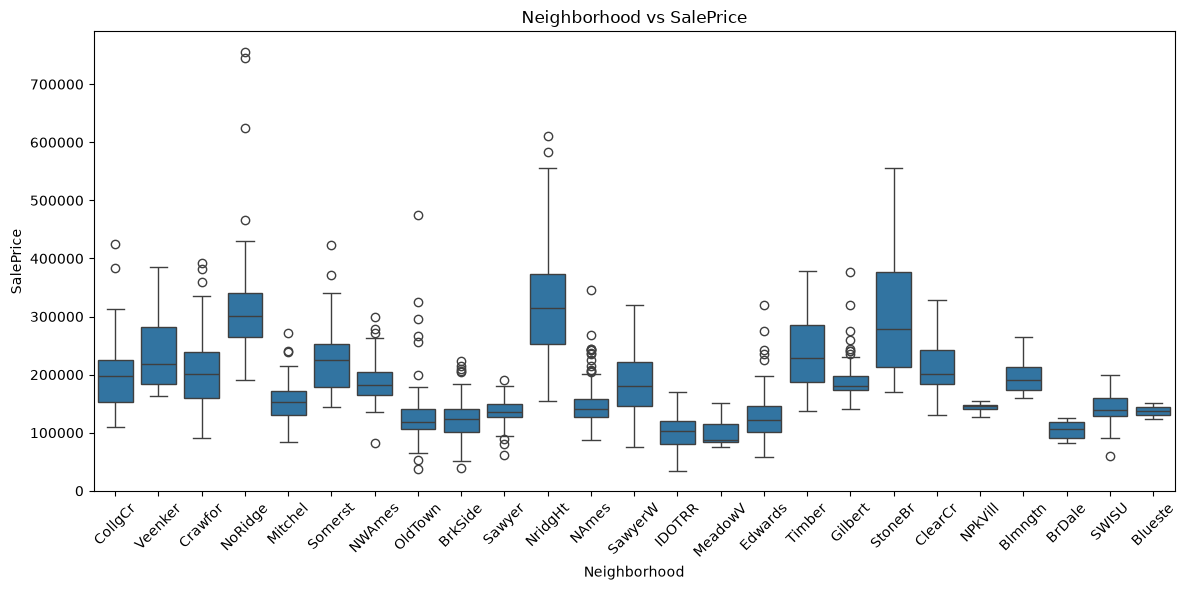

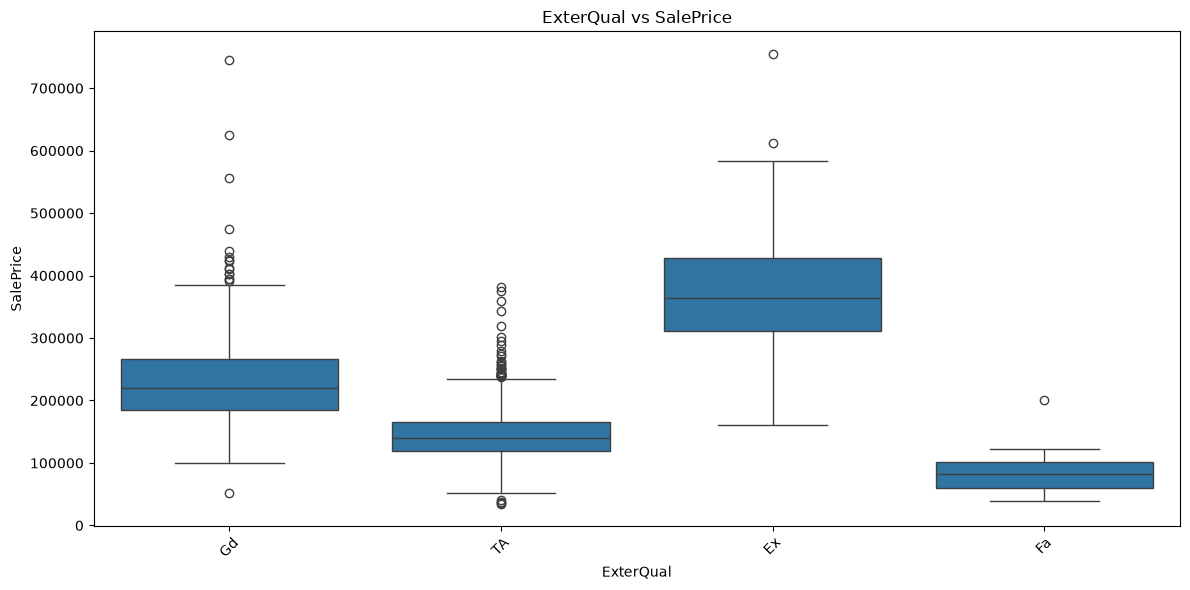

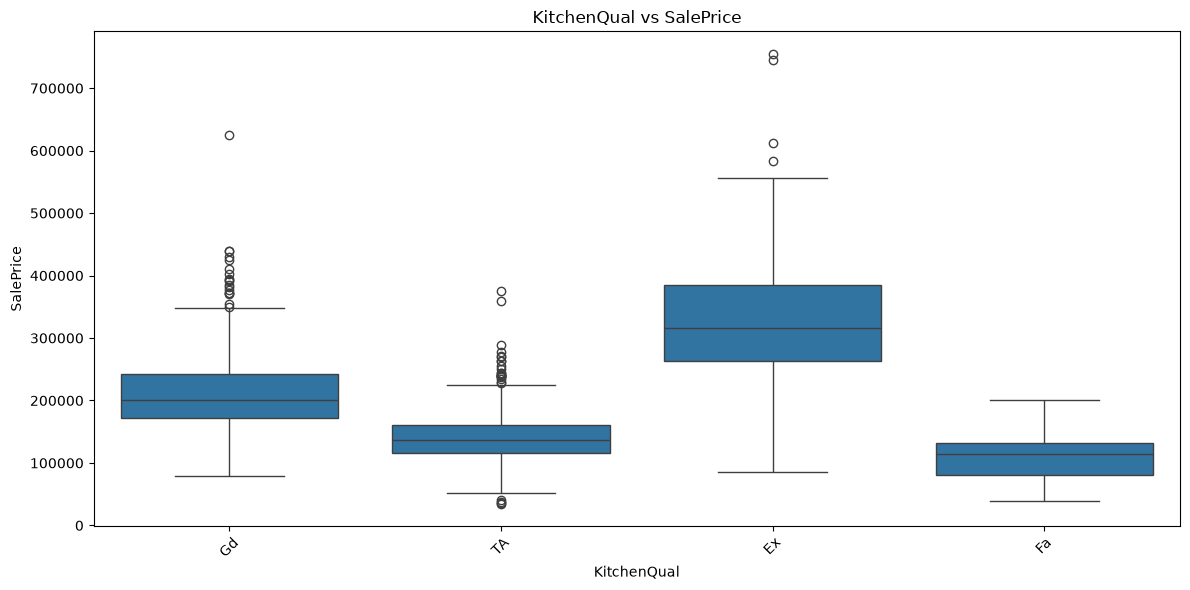

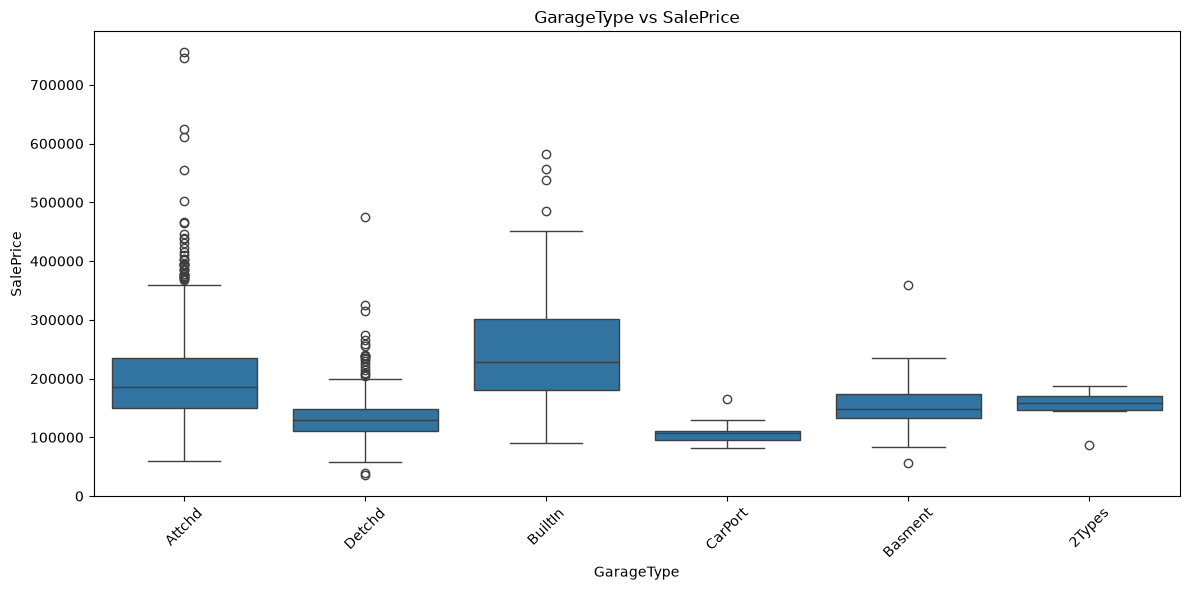

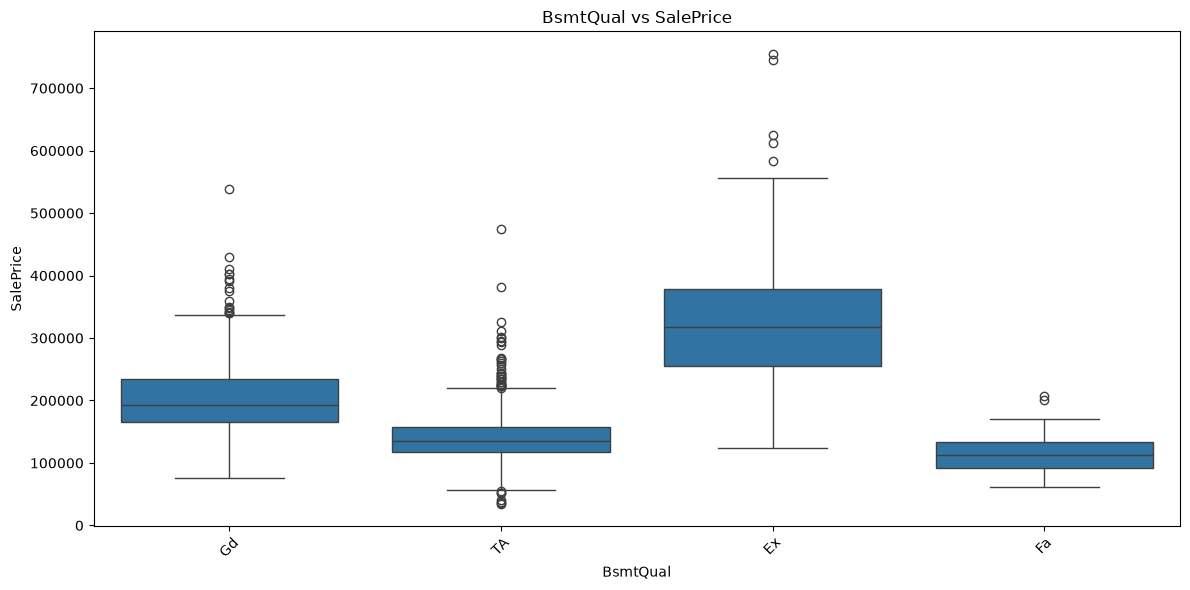

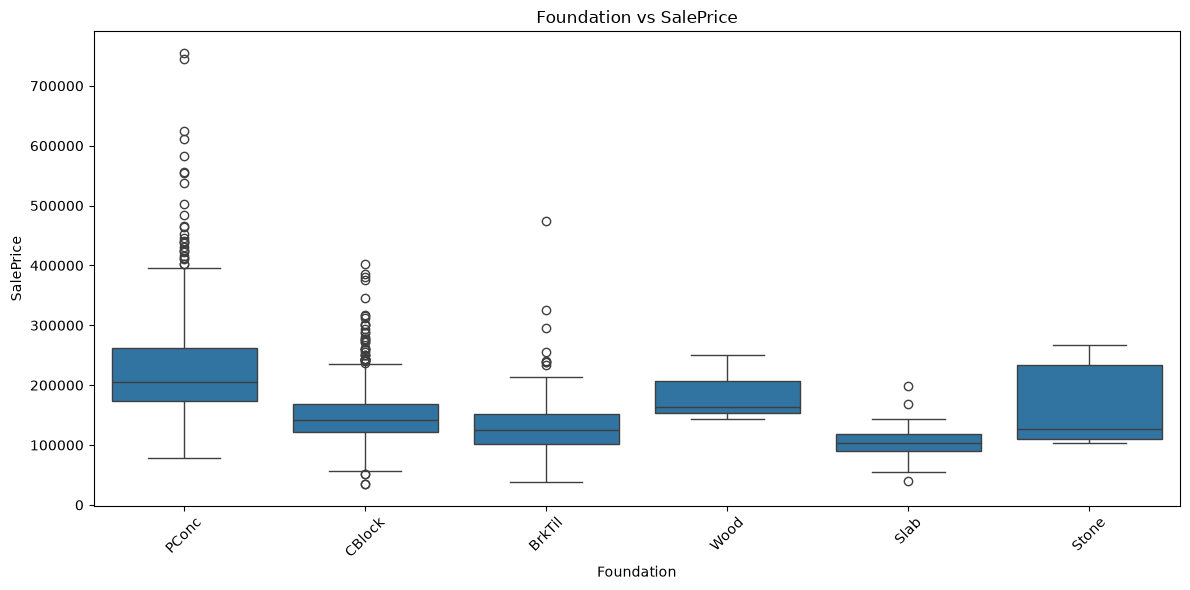

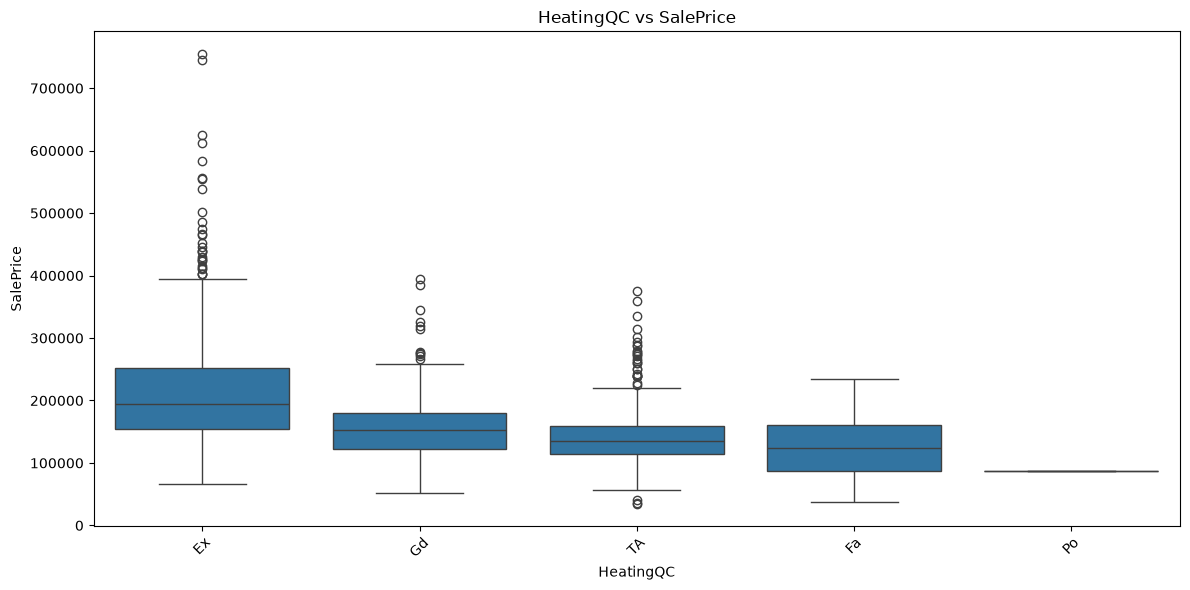

In [35]:
# Categorical Features vs SalePrice
for feature in important_categorical_features:

    plt.figure(figsize=(12, 6))

    sns.boxplot(
        data=train_df,
        x=feature,
        y="SalePrice"
    )

    plt.title(
        f"{feature} vs SalePrice"
    )

    plt.xticks(rotation=45)

    plt.tight_layout()
    plt.show()